## NB08 — Treinamento e Avaliação de Modelos

**Entrada:** `data/load/dataset_ml_model.csv` — 75.471 linhas × 26 colunas (gerado pelo NB07)

**Objetivo:** Treinar e avaliar o modelo de detecção de anomalias **Isolation Forest, LOF e One Class SVM** sobre o
dataset de propostas de licitações de Pernambuco (2020–2024).

In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.svm import OneClassSVM
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples

os.makedirs('data/load', exist_ok=True)
print('Setup OK')

Setup OK


In [2]:
import os
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

os.makedirs('figuras_tcc', exist_ok=True)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 200
plt.rcParams['axes.unicode_minus'] = True

def br(x, casas=0):
    """12345.678 -> '12.345,7' (ponto no milhar, vírgula decimal, sinal de menos correto)."""
    s = f'{round(x, casas) + 0.0:,.{casas}f}'  # '+ 0.0' evita '-0,00'
    return s.replace(',', '#').replace('.', ',').replace('#', '.').replace('-', '\u2212')

def fmt_eixo(ax, eixo='y', casas=0, pct=False):
    """Formato brasileiro nos números de um eixo. pct=True: multiplica por 100 e acrescenta '%'."""
    if pct:
        f = FuncFormatter(lambda v, _: br(v * 100, casas) + '%')
    else:
        f = FuncFormatter(lambda v, _: br(v, casas))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)

In [3]:
df = pd.read_csv('data/load/dataset_ml_model.csv')

print(f'Shape: {df.shape}')
print(f'\nColunas ({len(df.columns)}):')
print(list(df.columns))
print('\nTipos de dados:')
print(df.dtypes)
df.head(3)

Shape: (75471, 26)

Colunas (26):
['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp', 'numeroItem', 'cnpj_forn_norm', 'desvio_item_estimado', 'n_propostas_item', 'fornecedor_unico', 'ano', 'mes', 'trimestre', 'dia_semana', 'dias_desde_eleicao', 'pre_eleitoral_180d', 'pos_eleitoral_180d', 'fornecedor_fora_pe', 'tipo_fornecedor', 'idade_empresa_anos', 'empresa_nova', 'opcao_pelo_mei', 'opcao_pelo_simples', 'modalidade_Dispensa', 'modalidade_Inexigibilidade', 'modalidade_Licitacao', 'porte', 'descricao_situacao_cadastral']

Tipos de dados:
orgaoEntidadeCnpj                 int64
anoCompraPncp                     int64
sequencialCompraPncp              int64
numeroItem                        int64
cnpj_forn_norm                    int64
desvio_item_estimado            float64
n_propostas_item                  int64
fornecedor_unico                  int64
ano                               int64
mes                               int64
trimestre                         int64
dia_se

,orgaoEntidadeCnpj,anoCompraPncp,sequencialCompraPncp,numeroItem,cnpj_forn_norm,desvio_item_estimado,n_propostas_item,fornecedor_unico,ano,mes,...,tipo_fornecedor,idade_empresa_anos,empresa_nova,opcao_pelo_mei,opcao_pelo_simples,modalidade_Dispensa,modalidade_Inexigibilidade,modalidade_Licitacao,porte,descricao_situacao_cadastral
0,2030715000112,2023,1,1,44051659000142,-0.354518,1,1,2023,1,...,1,8.670773,0,0,0,1,0,0,0,0
1,2030715000112,2023,3,1,44051659000142,-0.019704,1,1,2023,1,...,1,8.670773,0,0,0,1,0,0,0,0
2,508903000188,2022,324,1,32212672000157,0.000000,1,1,2023,1,...,1,8.670773,0,0,0,1,0,0,0,0


---
### 1. Preparação: Remoção de Identificadores

In [4]:
identificadores = ['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp',
                   'numeroItem', 'cnpj_forn_norm']

df = df.drop(identificadores, axis=1)
df

,desvio_item_estimado,n_propostas_item,fornecedor_unico,ano,mes,trimestre,dia_semana,dias_desde_eleicao,pre_eleitoral_180d,pos_eleitoral_180d,...,tipo_fornecedor,idade_empresa_anos,empresa_nova,opcao_pelo_mei,opcao_pelo_simples,modalidade_Dispensa,modalidade_Inexigibilidade,modalidade_Licitacao,porte,descricao_situacao_cadastral
0,-0.354518,1,1,2023,1,1,0,-636,0,0,...,1,8.670773,0,0,0,1,0,0,0,0
1,-0.019704,1,1,2023,1,1,1,-635,0,0,...,1,8.670773,0,0,0,1,0,0,0,0
2,0.000000,1,1,2023,1,1,4,-625,0,0,...,1,8.670773,0,0,0,1,0,0,0,0
3,-0.006719,1,1,2023,1,1,0,-636,0,0,...,1,8.670773,0,0,0,1,0,0,0,0
4,0.000000,1,1,2023,1,1,0,-622,0,0,...,1,8.670773,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75466,-0.000100,1,1,2024,12,4,2,73,0,1,...,1,8.670773,0,0,0,0,0,1,0,0
75467,-0.000100,1,1,2024,12,4,2,73,0,1,...,1,8.670773,0,0,0,0,0,1,0,0
75468,-0.000089,1,1,2024,12,4,2,73,0,1,...,1,8.670773,0,0,0,0,0,1,0,0
75469,-0.000092,1,1,2024,12,4,2,73,0,1,...,1,8.670773,0,0,0,0,0,1,0,0


---
### 2. Treinamento 

### Isolation Forest

O **Isolation Forest** detecta anomalias isolando observações com árvores de decisão aleatórias.
Pontos anômalos são isolados com menos cortes do que pontos normais, resultando em um
`anomaly_score` mais negativo.

**Hiperparâmetros:**

| Parâmetro | Valor | Justificativa |
|---|---|---|
| `n_estimators` | 100 | Número de árvores — bom equilíbrio entre estabilidade e custo computacional |
| `contamination` | 0.01 | 1% de anomalias esperadas — conservador, alinhado com Araújo et al. (2024) |
| `max_samples` | 256 | Amostras por árvore — padrão do sklearn, eficiente em datasets grandes |
| `random_state` | 42 | Reprodutibilidade dos resultados |

In [5]:
# Train Isolation Forest
iso_forest = IsolationForest(n_estimators=100,
                            contamination=0.01, # Expected proportion of anomalies
                            max_samples=256, # Number of samples used to train each tree
                            random_state=42)
iso_forest.fit(df)

IsolationForest(contamination=0.01, max_samples=256, random_state=42)

In [6]:
# 1 = normal ; -1 anomalo
feature_cols = df.columns.tolist()
df['anomaly_score'] = iso_forest.decision_function(df[feature_cols])
df['anomaly'] = iso_forest.predict(df[feature_cols])
df['anomaly'].value_counts()

anomaly
 1    74728
-1      743
Name: count, dtype: int64

### Resultados e Visualizações - Isolation Forest

#### Gráfico de dispersão (score × índice)

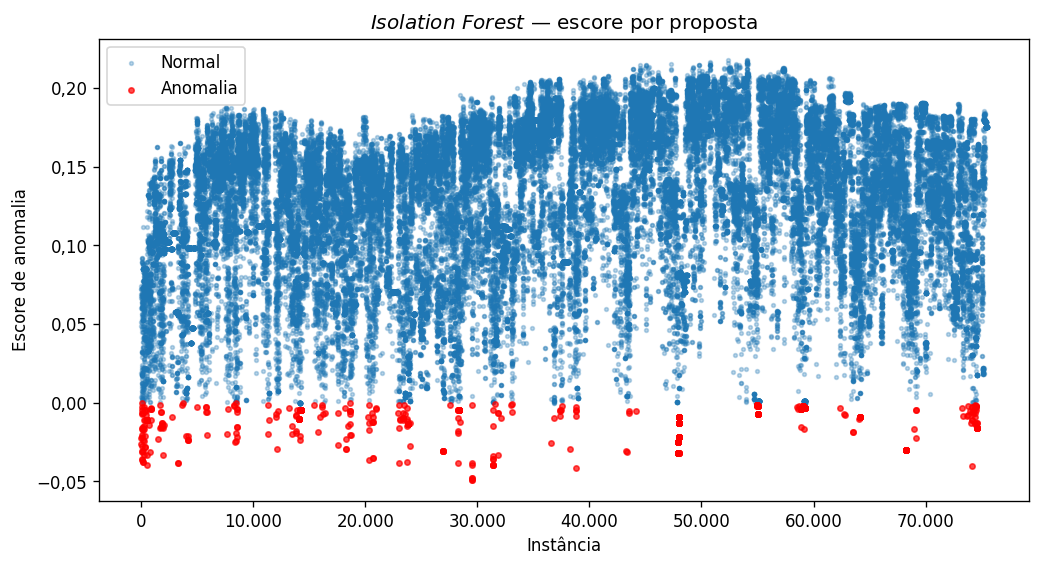

In [7]:
plt.figure(figsize=(10, 5))

normal = df[df['anomaly'] == 1]
plt.scatter(normal.index, normal['anomaly_score'], label='Normal', alpha=0.3, s=5)

anomalies = df[df['anomaly'] == -1]
plt.scatter(anomalies.index, anomalies['anomaly_score'], label='Anomalia', alpha=0.7, s=10, color='red')

plt.xlabel("Instância")
plt.ylabel("Escore de anomalia")
plt.title(r'$\mathit{Isolation\ Forest}$ — escore por proposta')
plt.legend()
fmt_eixo(plt.gca(), 'x', 0)
fmt_eixo(plt.gca(), 'y', 2)
plt.savefig('figuras_tcc/image15.png', dpi=200, bbox_inches='tight')
plt.show()

#### Histograma de distribuição

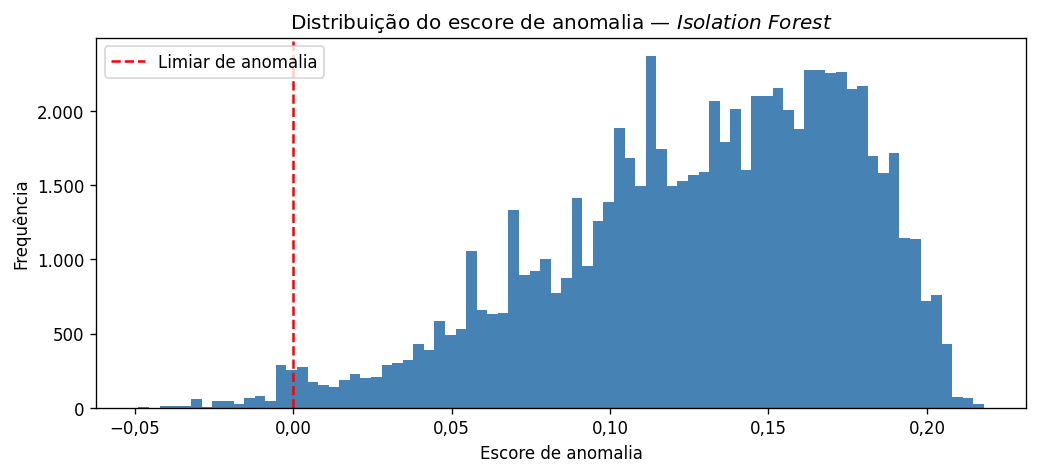

Total de anomalias detectadas: 743 (1.0%)


In [8]:
# Distribuição do anomaly_score
plt.figure(figsize=(10, 4))
plt.hist(df['anomaly_score'], bins=80, color='steelblue', edgecolor='none')
plt.axvline(df[df['anomaly'] == -1]['anomaly_score'].max(), color='red', linestyle='--', label='Limiar de anomalia')
plt.xlabel("Escore de anomalia")
plt.ylabel("Frequência")
plt.title(r'Distribuição do escore de anomalia — $\mathit{Isolation\ Forest}$')
plt.legend()
fmt_eixo(plt.gca(), 'x', 2)
fmt_eixo(plt.gca(), 'y', 0)
plt.savefig('figuras_tcc/image6.png', dpi=200, bbox_inches='tight')
plt.show()

print(f"Total de anomalias detectadas: {(df['anomaly'] == -1).sum()} ({(df['anomaly'] == -1).mean():.1%})")

---
### Local Outlier Factor - LOF

O LOF depende de distâncias entre registros, então as features são padronizadas (`StandardScaler`) antes do ajuste. O Isolation Forest não precisa disso.
A comparação com o LOF sem padronização e com `RobustScaler` está no NB09 (seção 2.4).

In [9]:
# testar com valores diferentes de neighbors
X_lof = StandardScaler().fit_transform(df[feature_cols])
lof = LocalOutlierFactor(n_neighbors=50, contamination=0.01)

lof_predictions = lof.fit_predict(X_lof)
lof_scores = -lof.negative_outlier_factor_

# (Higher score = more anomalous. Standard values close to or > 1 indicate outliers)
df['lof_anomaly_score'] = lof_scores
df['lof_anomaly'] = lof_predictions

print(f"Total de propostas: {len(df)}")
print(f"Anomalias detectadas: {(df['lof_anomaly'] == -1).sum()} ({(df['lof_anomaly'] == -1).mean():.1%})")
df['lof_anomaly'].value_counts()

Total de propostas: 75471
Anomalias detectadas: 755 (1.0%)


/Users/lgs/Library/Python/3.9/lib/python/site-packages/sklearn/neighbors/_lof.py:322: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(


lof_anomaly
 1    74716
-1      755
Name: count, dtype: int64

### Resultados e Visualizações - LOF

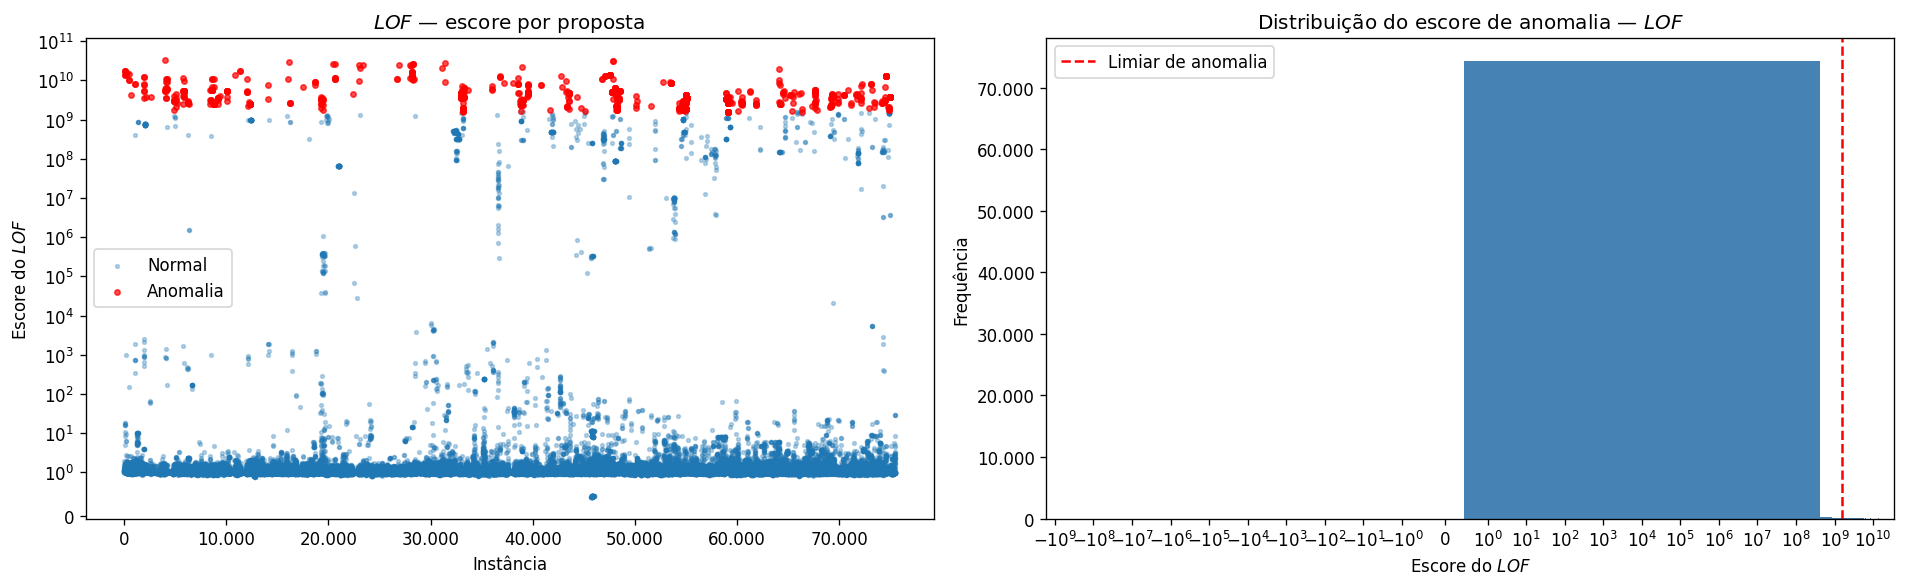

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

normal = df[df['lof_anomaly'] == 1]
anomalies = df[df['lof_anomaly'] == -1]

axes[0].scatter(normal.index, normal['lof_anomaly_score'], label='Normal', alpha=0.3, s=5)
axes[0].scatter(anomalies.index, anomalies['lof_anomaly_score'], label='Anomalia', alpha=0.7, s=10, color='red')
axes[0].set_xlabel("Instância")
axes[0].set_ylabel(r'Escore do $\mathit{LOF}$')
axes[0].set_title(r'$\mathit{LOF}$ — escore por proposta')
axes[0].set_yscale('symlog', linthresh=1)  # escala simétrica-log: evita notação científica (1e14)
axes[0].legend()
fmt_eixo(axes[0], 'x', 0)

axes[1].hist(df['lof_anomaly_score'], bins=80, color='steelblue', edgecolor='none')
axes[1].axvline(df[df['lof_anomaly'] == -1]['lof_anomaly_score'].min(),
                color='red', linestyle='--', label='Limiar de anomalia')
axes[1].set_xlabel(r'Escore do $\mathit{LOF}$')
axes[1].set_ylabel("Frequência")
axes[1].set_title(r'Distribuição do escore de anomalia — $\mathit{LOF}$')
axes[1].set_xscale('symlog', linthresh=1)
axes[1].legend()
fmt_eixo(axes[1], 'y', 0)

plt.tight_layout()
plt.savefig('figuras_tcc/image2.png', dpi=200, bbox_inches='tight')
plt.show()

--- 
### One Class SVM

In [11]:
ocsvm = OneClassSVM(kernel='rbf', nu=0.01, gamma='scale')
ocsvm.fit(df[feature_cols])

ocsvm_predictions = ocsvm.predict(df[feature_cols])
ocsvm_scores = ocsvm.decision_function(df[feature_cols])

df['ocsvm_anomaly_score'] = ocsvm_scores
df['ocsvm_anomaly'] = ocsvm_predictions

print(f"Total de propostas: {len(df)}")
print(f"Anomalias detectadas: {(df['ocsvm_anomaly'] == -1).sum()} ({(df['ocsvm_anomaly'] == -1).mean():.1%})")
df['ocsvm_anomaly'].value_counts()

Total de propostas: 75471
Anomalias detectadas: 729 (1.0%)


ocsvm_anomaly
 1    74742
-1      729
Name: count, dtype: int64

### Resultados e Visualizações - One Class SVM

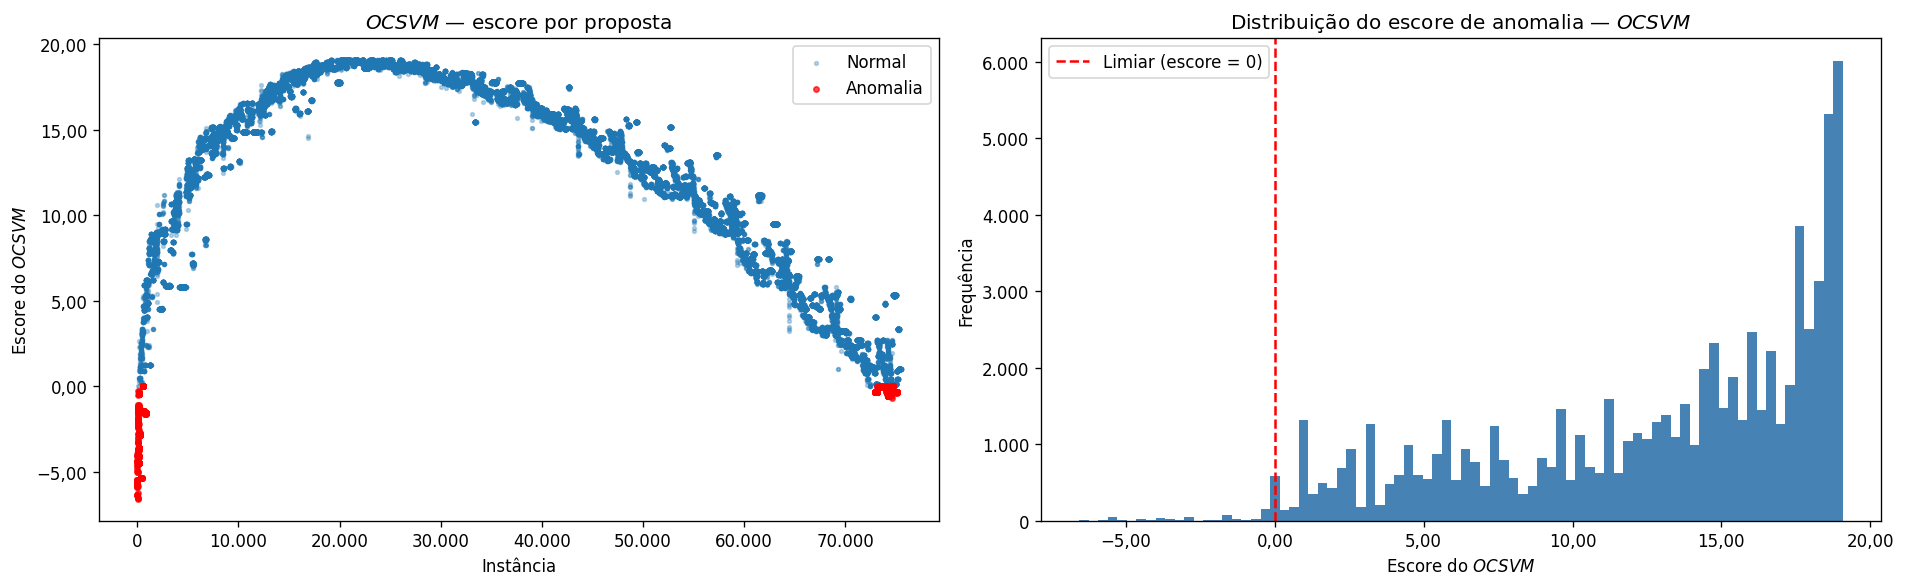

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Scatter: escore × índice
normal = df[df['ocsvm_anomaly'] == 1]
anomalies = df[df['ocsvm_anomaly'] == -1]

axes[0].scatter(normal.index, normal['ocsvm_anomaly_score'], label='Normal', alpha=0.3, s=5)
axes[0].scatter(anomalies.index, anomalies['ocsvm_anomaly_score'], label='Anomalia', alpha=0.7, s=10, color='red')
axes[0].set_xlabel("Instância")
axes[0].set_ylabel(r'Escore do $\mathit{OCSVM}$')
axes[0].set_title(r'$\mathit{OCSVM}$ — escore por proposta')
axes[0].legend()
fmt_eixo(axes[0], 'x', 0)
fmt_eixo(axes[0], 'y', 2)

# Histograma
axes[1].hist(df['ocsvm_anomaly_score'], bins=80, color='steelblue', edgecolor='none')
axes[1].axvline(0, color='red', linestyle='--', label='Limiar (escore = 0)')
axes[1].set_xlabel(r'Escore do $\mathit{OCSVM}$')
axes[1].set_ylabel("Frequência")
axes[1].set_title(r'Distribuição do escore de anomalia — $\mathit{OCSVM}$')
axes[1].legend()
fmt_eixo(axes[1], 'x', 2)
fmt_eixo(axes[1], 'y', 0)

plt.tight_layout()
plt.savefig('figuras_tcc/image14.png', dpi=200, bbox_inches='tight')
plt.show()

### Nomalização das Features - One Class SVM

In [13]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[feature_cols])

ocsvm = OneClassSVM(kernel='rbf', nu=0.01, gamma='scale')
ocsvm.fit(X_scaled)

ocsvm_predictions = ocsvm.predict(X_scaled)
ocsvm_scores = ocsvm.decision_function(X_scaled)

df['ocsvm_anomaly_score'] = ocsvm_scores
df['ocsvm_anomaly'] = ocsvm_predictions

print(f"Total de propostas: {len(df)}")
print(f"Anomalias detectadas (pós normalização): {(df['ocsvm_anomaly'] == -1).sum()} ({(df['ocsvm_anomaly'] == -1).mean():.1%})")
df['ocsvm_anomaly'].value_counts()

Total de propostas: 75471
Anomalias detectadas (pós normalização): 816 (1.1%)


ocsvm_anomaly
 1    74655
-1      816
Name: count, dtype: int64

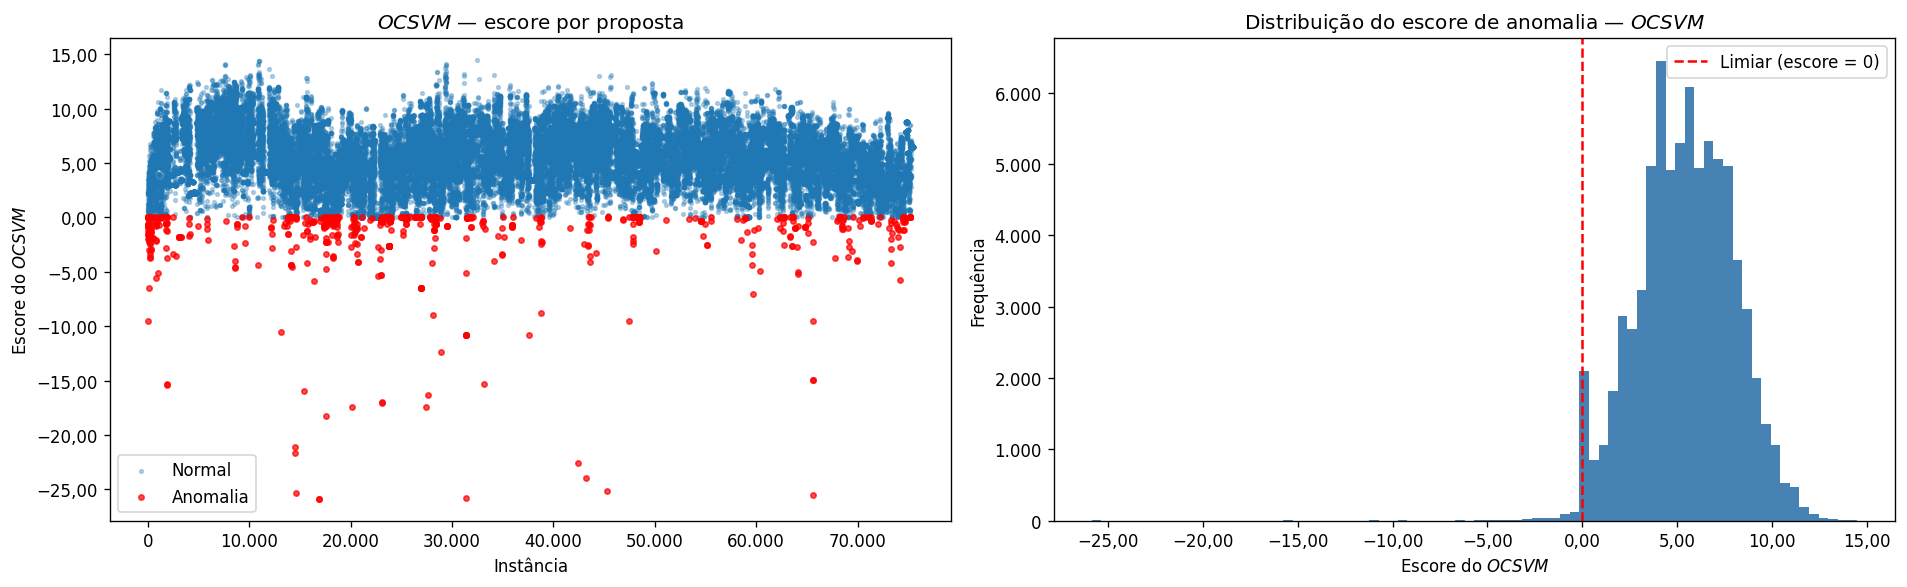

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Scatter: escore × índice
normal = df[df['ocsvm_anomaly'] == 1]
anomalies = df[df['ocsvm_anomaly'] == -1]

axes[0].scatter(normal.index, normal['ocsvm_anomaly_score'], label='Normal', alpha=0.3, s=5)
axes[0].scatter(anomalies.index, anomalies['ocsvm_anomaly_score'], label='Anomalia', alpha=0.7, s=10, color='red')
axes[0].set_xlabel("Instância")
axes[0].set_ylabel(r'Escore do $\mathit{OCSVM}$')
axes[0].set_title(r'$\mathit{OCSVM}$ — escore por proposta')
axes[0].legend()
fmt_eixo(axes[0], 'x', 0)
fmt_eixo(axes[0], 'y', 2)

# Histograma
axes[1].hist(df['ocsvm_anomaly_score'], bins=80, color='steelblue', edgecolor='none')
axes[1].axvline(0, color='red', linestyle='--', label='Limiar (escore = 0)')
axes[1].set_xlabel(r'Escore do $\mathit{OCSVM}$')
axes[1].set_ylabel("Frequência")
axes[1].set_title(r'Distribuição do escore de anomalia — $\mathit{OCSVM}$')
axes[1].legend()
fmt_eixo(axes[1], 'x', 2)
fmt_eixo(axes[1], 'y', 0)

plt.tight_layout()
plt.savefig('figuras_tcc/image11.png', dpi=200, bbox_inches='tight')
plt.show()

---
### Silhouette Score — Qualidade da Separação entre Normal e Anômalo

O **Silhouette Score** mede o quão bem separados estão os dois grupos criados por cada modelo
(normal vs. anomalia) no espaço de features. Varia de **-1 a +1**:

| Faixa | Interpretação |
|---|---|
| Próximo de +1 | Grupos bem separados e compactos |
| Próximo de 0 | Grupos sobrepostos / fronteira difusa |
| Negativo | Pontos mal classificados (na região errada) |

Como o dataset tem 75.471 registros e o silhouette é O(n²), o cálculo é feito sobre
uma **amostra aleatória estratificada de 5.000 registros** com `random_state=42`.
As features são normalizadas com `StandardScaler` para garantir comparação justa entre modelos.

=== Silhouette Score (amostra n=5000) ===
  Isolation Forest : 0.4415
  LOF              : 0.0883
  One-Class SVM    : 0.4163


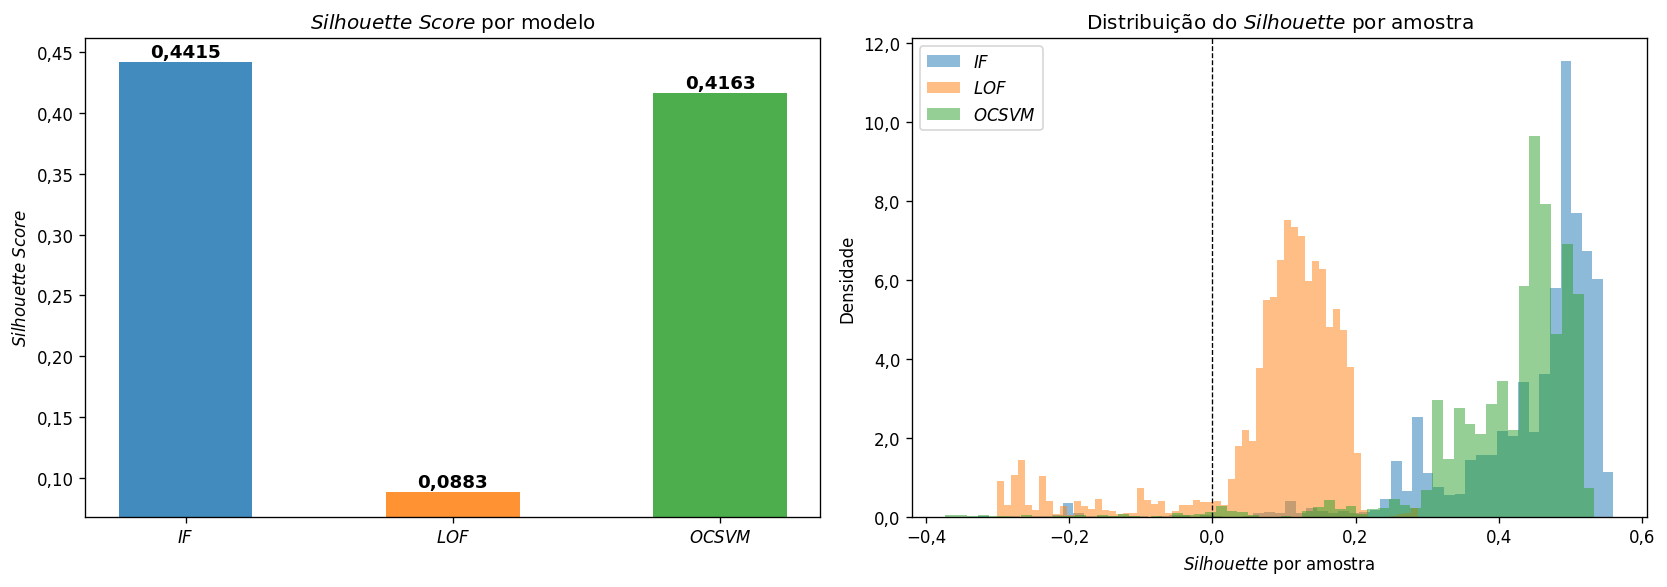

In [15]:
SAMPLE_SIZE = 5000
np.random.seed(42)
idx = np.random.choice(len(df), size=SAMPLE_SIZE, replace=False)

scaler_sil = StandardScaler()
X_sil = scaler_sil.fit_transform(df.iloc[idx][feature_cols])

labels_if    = df.iloc[idx]['anomaly'].values
labels_lof   = df.iloc[idx]['lof_anomaly'].values
labels_ocsvm = df.iloc[idx]['ocsvm_anomaly'].values

sil_if    = silhouette_score(X_sil, labels_if)
sil_lof   = silhouette_score(X_sil, labels_lof)
sil_ocsvm = silhouette_score(X_sil, labels_ocsvm)

print(f'=== Silhouette Score (amostra n={SAMPLE_SIZE}) ===')
print(f'  Isolation Forest : {sil_if:.4f}')
print(f'  LOF              : {sil_lof:.4f}')
print(f'  One-Class SVM    : {sil_ocsvm:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

modelos = [r'$\mathit{IF}$', r'$\mathit{LOF}$', r'$\mathit{OCSVM}$']
scores  = [sil_if, sil_lof, sil_ocsvm]
cores   = ['#1f77b4', '#ff7f0e', '#2ca02c']

bars = axes[0].bar(modelos, scores, color=cores, alpha=0.85, width=0.5)
axes[0].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[0].set_ylim(min(scores) - 0.02, max(scores) + 0.02)
axes[0].set_ylabel(r'$\mathit{Silhouette\ Score}$')
axes[0].set_title(r'$\mathit{Silhouette\ Score}$ por modelo')
fmt_eixo(axes[0], 'y', 2)
for bar, val in zip(bars, scores):
    axes[0].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.001,
                 br(val, 4), ha='center', va='bottom', fontsize=11, fontweight='bold')

sil_samples_if    = silhouette_samples(X_sil, labels_if)
sil_samples_lof   = silhouette_samples(X_sil, labels_lof)
sil_samples_ocsvm = silhouette_samples(X_sil, labels_ocsvm)

axes[1].hist(sil_samples_if,    bins=60, alpha=0.5, color='#1f77b4', label=r'$\mathit{IF}$',    density=True)
axes[1].hist(sil_samples_lof,   bins=60, alpha=0.5, color='#ff7f0e', label=r'$\mathit{LOF}$',   density=True)
axes[1].hist(sil_samples_ocsvm, bins=60, alpha=0.5, color='#2ca02c', label=r'$\mathit{OCSVM}$', density=True)
axes[1].axvline(0, color='black', linewidth=0.8, linestyle='--')
axes[1].set_xlabel(r'$\mathit{Silhouette}$ por amostra')
axes[1].set_ylabel('Densidade')
axes[1].set_title(r'Distribuição do $\mathit{Silhouette}$ por amostra')
axes[1].legend()
fmt_eixo(axes[1], 'x', 1)
fmt_eixo(axes[1], 'y', 1)

plt.tight_layout()
plt.savefig('figuras_tcc/image10.png', dpi=200, bbox_inches='tight')
plt.show()